# H&M Müşteri ve Satış Analizi (SQL)

**İş sorusu:** H&M'nin müşterileri kim, ne zaman ve nasıl alışveriş yapıyor? Bulgulara dayanarak hangi pazarlama ve stok kararları alınabilir?

**Veri:** H&M Personalized Fashion Recommendations (Kaggle). 31,8 milyon satış, 1,37 milyon müşteri, 105 bin ürün; 20.09.2018 – 22.09.2020.
Veri boyutu ve yarışma kuralları nedeniyle depoda paylaşılmamıştır; [Kaggle'dan](https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/data) `articles.csv`, `customers.csv` ve `transactions_train.csv` dosyaları indirilip bu klasöre konmalıdır.

**Araçlar:** SQL (DuckDB) · Python (pandas, matplotlib, scipy)

## 0. Kurulum

In [2]:
import os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

os.makedirs("figures", exist_ok=True)

MAVI, TURUNCU, GRI = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titlesize": 12})

con = duckdb.connect("hm.duckdb")
con.sql("CREATE TABLE IF NOT EXISTS articles     AS SELECT * FROM read_csv_auto('articles.csv')")
con.sql("CREATE TABLE IF NOT EXISTS customers    AS SELECT * FROM read_csv_auto('customers.csv')")
con.sql("CREATE TABLE IF NOT EXISTS transactions AS SELECT * FROM read_csv_auto('transactions_train.csv')")

def sql(sorgu):
    """SQL sorgusunu çalıştırıp sonucu pandas tablosu olarak döndürür."""
    return con.sql(sorgu).df()

# Yaş gruplarını tanımlayan ifade; birden fazla sorguda kullanılıyor
YAS_GRUBU = """CASE
        WHEN c.age < 25 THEN '16-24'
        WHEN c.age < 35 THEN '25-34'
        WHEN c.age < 45 THEN '35-44'
        WHEN c.age < 55 THEN '45-54'
        WHEN c.age < 65 THEN '55-64'
        WHEN c.age >= 65 THEN '65+'
        ELSE 'Bilinmiyor'
    END"""

## 1. Veriyi tanıma

Analize başlamadan önce tabloların eksiksiz yüklendiğini ve verinin hangi dönemi kapsadığını kontrol ediyoruz.

In [3]:
sql("""
SELECT 'articles' AS tablo, COUNT(*) AS satir_sayisi FROM articles
UNION ALL SELECT 'customers', COUNT(*) FROM customers
UNION ALL SELECT 'transactions', COUNT(*) FROM transactions
""")

,tablo,satir_sayisi
0,articles,105542
1,customers,1371980
2,transactions,31788324


In [4]:
sql("SELECT MIN(t_dat) AS ilk_tarih, MAX(t_dat) AS son_tarih FROM transactions")

,ilk_tarih,son_tarih
0,2018-09-20,2020-09-22


## 2. Eksik veriler: NULL her zaman "bilgi yok" mu?

`age` sütununda eksik değer azken `FN` (moda bülteni) sütununun büyük kısmı boş. Eksik satırları körü körüne silmek, müşterilerin üçte ikisini atıp yalnızca bülten abonelerini bırakacağı için **seçim yanlılığına** yol açardı.

In [5]:
sql("""
SELECT COUNT(*)                                   AS toplam_musteri,
       COUNT(*) - COUNT(age)                      AS yasi_eksik,
       ROUND(100.0 * (COUNT(*) - COUNT(age)) / COUNT(*), 1) AS yasi_eksik_yuzde,
       COUNT(*) - COUNT(FN)                       AS FN_eksik,
       ROUND(100.0 * (COUNT(*) - COUNT(FN)) / COUNT(*), 1)  AS FN_eksik_yuzde
FROM customers
""")

,toplam_musteri,yasi_eksik,yasi_eksik_yuzde,FN_eksik,FN_eksik_yuzde
0,1371980,15861,1.2,895050,65.2


`FN` boşluklarının anlamını, bülten sıklığını gösteren ikinci bir sütunla **çapraz doğrulayarak** test ediyoruz:

In [6]:
sql("""
SELECT FN, fashion_news_frequency, COUNT(*) AS musteri_sayisi
FROM customers
GROUP BY FN, fashion_news_frequency
ORDER BY musteri_sayisi DESC
""")

,FN,fashion_news_frequency,musteri_sayisi
0,NaN,NONE,876922
1,1.0,Regularly,475310
2,NaN,NaN,16009
3,NaN,Regularly,2106
4,1.0,Monthly,829
5,1.0,NONE,789
6,NaN,Monthly,13
7,1.0,None,2


**Yorum:** Müşterilerin yaklaşık %98,6'sında iki sütun uyumlu: `FN` boş olanların bülten sıklığı *NONE*, `FN = 1` olanlarınki *Regularly*. Yani `FN` boşluğu **"abone değil"** anlamına geliyor; bu satırlar silinmedi.
Yaşı eksik müşteriler (%1,2) yalnızca yaş analizlerinin dışında bırakıldı.

## 3. Müşteriler kaç yaşında?

In [7]:
yas = sql(f"""
SELECT {YAS_GRUBU.replace("c.age", "age")} AS yas_grubu,
       COUNT(*) AS musteri_sayisi,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS yuzde
FROM customers
GROUP BY yas_grubu
ORDER BY yas_grubu
""")
yas

,yas_grubu,musteri_sayisi,yuzde
0,16-24,357169,26.0
1,25-34,393292,28.7
2,35-44,169041,12.3
3,45-54,253951,18.5
4,55-64,139064,10.1
5,65+,43602,3.2
6,Bilinmiyor,15861,1.2


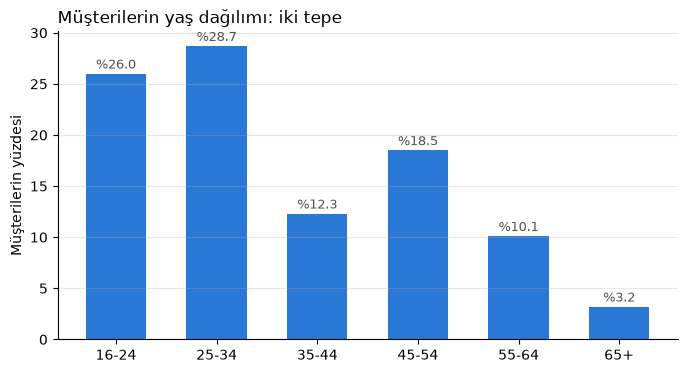

In [8]:
y = yas[yas["yas_grubu"] != "Bilinmiyor"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(y["yas_grubu"], y["yuzde"], color=MAVI, width=0.6)
for i, v in enumerate(y["yuzde"]):
    ax.text(i, v + 0.5, f"%{v:.1f}", ha="center", fontsize=9, color=GRI)
ax.set_title("Müşterilerin yaş dağılımı: iki tepe")
ax.set_ylabel("Müşterilerin yüzdesi")
ax.grid(axis="y", alpha=0.3)
fig.savefig("figures/yas_dagilimi.png", dpi=200, bbox_inches="tight")
plt.show()

**Yorum:** Dağılım **iki tepeli**: müşterilerin %55'i 16–34 yaşında, ikinci tepe 45–54 yaş grubunda (%18,5). Medyan (32) ve ortalama (36) birbirine yakın olsa da iki ayrı müşteri kitlesini tek bir sayıda gizliyor; bu yüzden dağılımın şekline bakmak gerekiyor.

## 4. Hangi yaş grubu ne alıyor? (üç tablonun birleştirilmesi)

**Hipotez:** 45–54 yaş grubu çocukları için alışveriş yaptığından daha fazla çocuk ürünü alıyor.

In [9]:
sql(f"""
SELECT {YAS_GRUBU} AS yas_grubu,
       COUNT(*) AS satis_sayisi,
       ROUND(100 * AVG(CASE WHEN a.index_group_name = 'Baby/Children' THEN 1 ELSE 0 END), 1) AS cocuk_yuzde,
       ROUND(100 * AVG(CASE WHEN a.index_group_name = 'Divided'       THEN 1 ELSE 0 END), 1) AS divided_yuzde,
       ROUND(100 * AVG(CASE WHEN a.index_group_name = 'Ladieswear'    THEN 1 ELSE 0 END), 1) AS kadin_yuzde
FROM transactions AS t
JOIN customers AS c ON t.customer_id = c.customer_id
JOIN articles  AS a ON t.article_id  = a.article_id
GROUP BY yas_grubu
ORDER BY yas_grubu
""")

,yas_grubu,satis_sayisi,cocuk_yuzde,divided_yuzde,kadin_yuzde
0,16-24,6525051,1.3,29.1,61.1
1,25-34,11565068,2.5,21.8,66.3
2,35-44,4111309,10.2,19.7,61.2
3,45-54,6079556,5.4,21.1,62.4
4,55-64,2793745,2.2,18.0,69.3
5,65+,573337,3.5,15.3,73.5
6,Bilinmiyor,140258,7.5,20.9,61.5


**Yorum:** Hipotez **yanlışlandı.** Çocuk ürünü alımı 45–54'te değil, **35–44 yaşta zirve yapıyor** (%10,2; diğer grupların 2–8 katı): küçük çocuklu ebeveynlerin yaşı. Genç koleksiyon *Divided* en çok 16–24 yaş grubuna satıyor (%29); kadın giyiminin payı yaşla birlikte artıyor.

## 5. Yaş gruplarının alışveriş davranışı

In [10]:
sql(f"""
SELECT {YAS_GRUBU} AS yas_grubu,
       COUNT(DISTINCT t.customer_id) AS aktif_musteri,
       ROUND(COUNT(DISTINCT t.customer_id || '-' || t.t_dat) / COUNT(DISTINCT t.customer_id), 1) AS musteri_basina_alisveris,
       ROUND(COUNT(*) / COUNT(DISTINCT t.customer_id || '-' || t.t_dat), 2) AS sepet_buyuklugu
FROM transactions AS t
JOIN customers AS c ON t.customer_id = c.customer_id
GROUP BY yas_grubu
ORDER BY yas_grubu
""")

,yas_grubu,aktif_musteri,musteri_basina_alisveris,sepet_buyuklugu
0,16-24,353827,6.0,3.09
1,25-34,391009,7.5,3.95
2,35-44,167950,6.2,3.92
3,45-54,252409,7.1,3.41
4,55-64,138099,6.7,3.02
5,65+,43226,5.6,2.38
6,Bilinmiyor,15761,2.9,3.02


*Aynı müşterinin aynı gündeki satın almaları tek alışveriş (sepet) olarak kabul edildi.*

**Yorum:** **25–34** en değerli grup: en sık alışveriş yapan (iki yılda ortalama 7,5 gün) ve en büyük sepeti dolduran (3,95 ürün) grup. **45–54** ise sepetleri küçük olsa da ikinci en sık gelen grup, yani **sadık** müşteriler. 35–44 az geliyor ama geldiğinde büyük sepetle alışveriş yapıyor.

## 6. Mevsimsellik: satışlar yıl içinde nasıl değişiyor?

In [11]:
aylik = sql("""
SELECT DATE_TRUNC('month', t_dat) AS ay,
       COUNT(*) AS satis_sayisi,
       ROUND(100 * AVG(CASE WHEN sales_channel_id = 2 THEN 1 ELSE 0 END), 1) AS online_yuzde
FROM transactions
GROUP BY ay
ORDER BY ay
""")
tam = aylik.iloc[1:-1]   # ilk ve son ay eksik (veri 20 Eylül'de başlayıp 22 Eylül'de bitiyor)
aylik

,ay,satis_sayisi,online_yuzde
0,2018-09-01,594776,65.1
1,2018-10-01,1397040,69.7
2,2018-11-01,1270619,71.7
3,2018-12-01,1148827,61.5
4,2019-01-01,1263471,73.8
5,2019-02-01,1152412,67.4
6,2019-03-01,1286750,71.9
7,2019-04-01,1476454,70.0
8,2019-05-01,1560319,68.5
9,2019-06-01,1906202,70.3


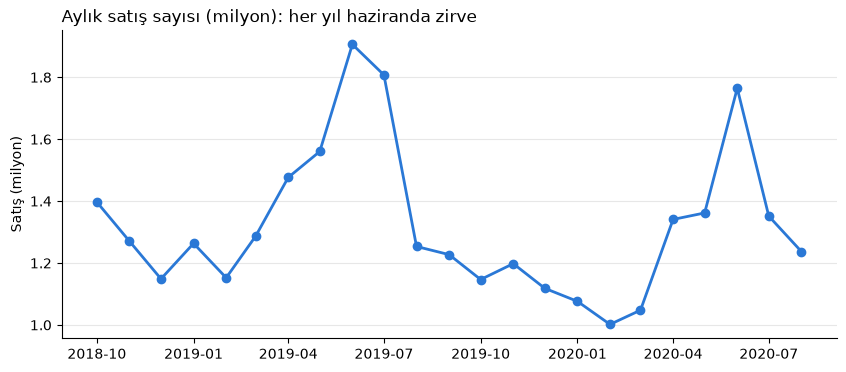

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tam["ay"], tam["satis_sayisi"] / 1_000_000, marker="o", color=MAVI, linewidth=2)
ax.set_title("Aylık satış sayısı (milyon): her yıl haziranda zirve")
ax.set_ylabel("Satış (milyon)")
ax.grid(axis="y", alpha=0.3)
fig.savefig("figures/aylik_satis.png", dpi=200, bbox_inches="tight")
plt.show()

**Yorum:** Satışlar ilkbaharda yükselip **her yıl haziranda zirve** yapıyor (2019: 1,91 M; 2020: 1,76 M); yaz koleksiyonu ve yaz indirimleri bu deseni açıklayabilir. Aralık beklenenin aksine yüksek değil. 2020'nin her ayı 2019'un gerisinde; düşüş pandemiden önce ocakta başlamış.
*Not: Eylül 2018 ve Eylül 2020 eksik ay olduğu için grafikten çıkarıldı.*

## 7. Pandemi: satışlar online'a mı kaydı?

`sales_channel_id` sütununun değerleri (1, 2) resmî olarak açıklanmamış; yaygın yorum 1 = mağaza, 2 = online. Mağazaların kapandığı dönemde kanal 2'nin payı artıyorsa bu yorum desteklenir.

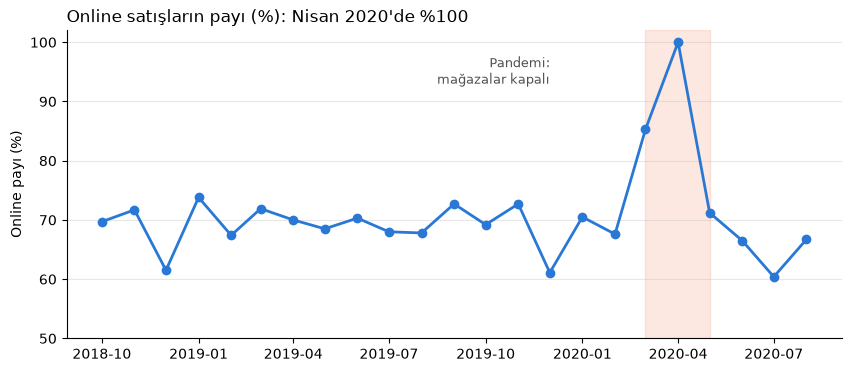

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tam["ay"], tam["online_yuzde"], marker="o", color=MAVI, linewidth=2)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-01"), color=TURUNCU, alpha=0.15)
ax.text(pd.Timestamp("2019-12-01"), 93, "Pandemi:\nmağazalar kapalı", fontsize=9, color=GRI, ha="right")
ax.set_title("Online satışların payı (%): Nisan 2020'de %100")
ax.set_ylabel("Online payı (%)")
ax.set_ylim(50, 102)
ax.grid(axis="y", alpha=0.3)
fig.savefig("figures/online_payi.png", dpi=200, bbox_inches="tight")
plt.show()

**Yorum:** Online payı normalde %60–75 arasında. Mart 2020'de %85'e, **Nisan 2020'de %100'e** çıkıyor; mayısta mağazalar açılınca %71'e dönüyor. Nisan'da mağaza kanalından tek satış yok: bu hem **1 = mağaza, 2 = online** yorumunu doğruluyor hem de pandeminin satışları tamamen online'a taşıdığını gösteriyor. Aralık aylarında ise mağaza payı yükseliyor (yılbaşı alışverişi).

**Sınırlılık:** Veri yalnızca müşteriye bağlanabilen satışları içerdiğinden (mağazada üyelik kartı okutulmayan alışverişler büyük olasılıkla yok) online payı gerçekte olduğundan yüksek görünüyor olabilir.

## 8. Müşteri sadakati: gelirin kaynağı kim?

In [14]:
sadakat = sql("""
WITH musteri_ozet AS (
    SELECT customer_id,
           COUNT(DISTINCT t_dat) AS alisveris_gunu,
           COUNT(*)              AS urun_sayisi
    FROM transactions
    GROUP BY customer_id
)
SELECT
    CASE
        WHEN alisveris_gunu = 1   THEN '1 kez'
        WHEN alisveris_gunu <= 3  THEN '2-3 kez'
        WHEN alisveris_gunu <= 10 THEN '4-10 kez'
        ELSE '10+ kez'
    END AS alisveris_sikligi,
    ROUND(100.0 * COUNT(*)         / SUM(COUNT(*))         OVER (), 1) AS musteri_yuzde,
    ROUND(100.0 * SUM(urun_sayisi) / SUM(SUM(urun_sayisi)) OVER (), 1) AS satis_yuzde
FROM musteri_ozet
GROUP BY alisveris_sikligi
ORDER BY MIN(alisveris_gunu)
""")
sadakat

,alisveris_sikligi,musteri_yuzde,satis_yuzde
0,1 kez,32.9,4.9
1,2-3 kez,21.8,7.9
2,4-10 kez,25.9,24.8
3,10+ kez,19.5,62.5


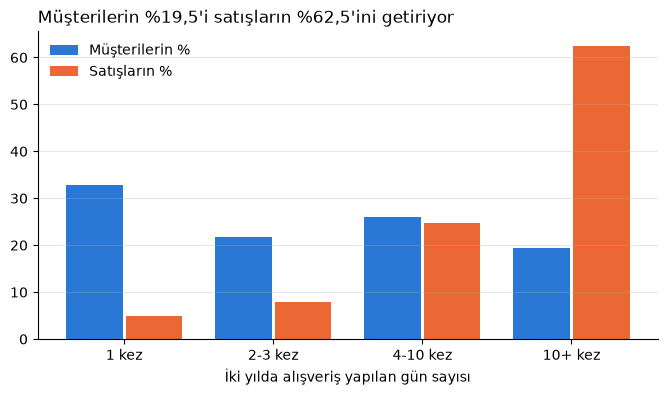

In [15]:
x = range(len(sadakat))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([i - 0.2 for i in x], sadakat["musteri_yuzde"], width=0.38, color=MAVI, label="Müşterilerin %")
ax.bar([i + 0.2 for i in x], sadakat["satis_yuzde"],   width=0.38, color=TURUNCU, label="Satışların %")
ax.set_xticks(list(x), sadakat["alisveris_sikligi"])
ax.set_xlabel("İki yılda alışveriş yapılan gün sayısı")
ax.set_title("Müşterilerin %19,5'i satışların %62,5'ini getiriyor")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
fig.savefig("figures/sadakat.png", dpi=200, bbox_inches="tight")
plt.show()

**Yorum:** İki yılda 10'dan fazla gün alışveriş yapan **%19,5'lik sadık çekirdek, satışların %62,5'ini** getiriyor (Pareto ilkesi). Tek seferlik müşteriler ise müşterilerin üçte birini oluşturmasına rağmen satışların yalnızca %5'ini getiriyor.

**Öneri:** Düzenli alışveriş yapan (4–10 kez) müşterileri sadık çekirdeğe kazandırmaya yönelik kampanyalar; sık gelen müşterilere yeni ürünleri öne çıkaran kişiselleştirilmiş içerikler.

**Sınırlılık:** Veri döneminin sonuna yakın ilk alışverişini yapan müşteriler geri dönme fırsatı bulamadığından tek seferlik müşteri oranı olduğundan yüksek görünebilir (sansürleme).

## 9. İstatistiksel test: yaş grupları farklı sıklıkta mı alışveriş yapıyor?

Alışveriş sayısı çarpık dağıldığından (çoğu müşteri birkaç kez, az sayıda müşteri çok sık geliyor) parametre dışı **Kruskal–Wallis** testi kullanıldı.

- H₀: Yaş gruplarının alışveriş sıklığı dağılımları aynıdır.
- H₁: En az bir grubun dağılımı farklıdır.

In [16]:
musteri = sql(f"""
SELECT {YAS_GRUBU} AS yas_grubu,
       COUNT(DISTINCT t.t_dat) AS alisveris_gunu
FROM transactions AS t
JOIN customers AS c ON t.customer_id = c.customer_id
WHERE c.age IS NOT NULL
GROUP BY t.customer_id, yas_grubu
""")
musteri.groupby("yas_grubu")["alisveris_gunu"].median()

yas_grubu
16-24    3.0
25-34    4.0
35-44    2.0
45-54    3.0
55-64    3.0
65+      2.0
Name: alisveris_gunu, dtype: float64

In [17]:
gruplar = [g["alisveris_gunu"] for _, g in musteri.groupby("yas_grubu")]
H, p = stats.kruskal(*gruplar)
n = len(musteri)
epsilon2 = H / (n - 1)
print(f"n = {n:,}")
print(f"H = {H:.1f}, p < 0.001" if p < 0.001 else f"H = {H:.1f}, p = {p:.4f}")
print(f"Etki büyüklüğü (epsilon kare) = {epsilon2:.4f}")

n = 1,346,520
H = 12022.3, p < 0.001
Etki büyüklüğü (epsilon kare) = 0.0089


**Yorum:** Fark istatistiksel olarak **anlamlı** (H ≈ 12.022, p < 0,001), ancak **etki büyüklüğü çok küçük** (ε² ≈ 0,009): yaş, alışveriş sıklığındaki farklılığın %1'inden azını açıklıyor.
1,35 milyon gözlemle çok küçük farklar bile anlamlı çıkar; bu nedenle p değerinin yanında etki büyüklüğü de raporlandı. **Pratik sonuç:** Yaş grupları arasındaki sıklık farkı gerçek ama küçük; sadakati yaştan çok başka etkenler belirliyor.

## 10. Bulguların özeti

1. Müşteri tabanı **iki tepeli**: 16–34 (%55) ve 45–54 (%18,5).
2. Çocuk ürünü alımı **35–44 yaşta zirve** yapıyor (%10,2); ilk hipotez yanlışlandı.
3. Genç koleksiyon *Divided* en çok **16–24** yaş grubuna satıyor (%29).
4. **25–34** en sık alışveriş yapan ve en büyük sepeti dolduran grup; **45–54** sadık, sık gelen müşteriler.
5. Satışlar **her yıl haziranda zirve** yapıyor.
6. Pandemi satışları **tamamen online'a** taşıdı: Nisan 2020'de satışların %100'ü online.
7. Müşterilerin **%19,5'i satışların %62,5'ini** getiriyor.
8. Yaş grupları arasındaki alışveriş sıklığı farkı anlamlı ama **etkisi küçük** (ε² ≈ 0,009).